# Processes & System Resources

Every running program is a **process** with its own memory and an ID. When a training job is slow, a server stops responding or a container is killed, you need to inspect processes and resources: CPU, memory and disk.

**After this lesson you can:**

1. List processes and explain PID, PPID and the process tree.
2. Run jobs in the background and stop them with signals.
3. Read CPU, memory and disk information from `/proc`, `free`, `df` and `psutil`.
4. Detect a memory leak by measuring a process over time, and explain the OOM killer.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

WORK = Path(tempfile.mkdtemp())          # a folder on the Linux file system (not on a Windows drive)
REPO = Path.cwd().parent                 # the course repository: real data for some examples

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def sh(cmd: str, cwd: Path = WORK, quiet: bool = False, check: bool = False) -> Output:
    """Run a command with bash, print the command and its output."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True)
    shorten = lambda t: t.replace(str(WORK), "<work>").replace(str(REPO), "<repo>")
    out = shorten((r.stdout + r.stderr).rstrip())
    if not quiet:
        print(f"$ {shorten(cmd)}" + (f"\n{out}" if out else ""))
    if check and r.returncode:
        raise RuntimeError(f"command failed with exit code {r.returncode}")
    return Output(r.stdout)

## 1. Processes

| Term | Meaning |
| :--- | :--- |
| **PID** | process ID, unique while the process runs |
| **PPID** | the PID of the parent process that started it |
| **RSS** | resident set size: the physical memory the process uses now |
| **state** | `R` running, `S` sleeping, `D` waiting for disk, `Z` zombie |

`ps` lists processes; `top` and `htop` show them live.

In [2]:
sh("ps -o pid,ppid,stat,rss,etime,comm -p $$ $PPID")       # this shell and its parent
sh("ps -e --no-headers | wc -l")                            # how many processes run on this machine

$ ps -o pid,ppid,stat,rss,etime,comm -p $$ $PPID
  PID  PPID STAT   RSS     ELAPSED COMMAND
68585 68501 Ssl  49624       00:04 python
68636 68585 R     2944       00:00 ps
$ ps -e --no-headers | wc -l
77


## 2. Background Jobs and Signals

A process receives **signals** from the kernel or from other processes:

| Signal | Number | Default effect | Can the program handle it? |
| :--- | :-: | :--- | :-: |
| `SIGTERM` | 15 | ask the process to stop (the default of `kill`) | yes: clean up, then exit |
| `SIGINT` | 2 | interrupt (Ctrl+C) | yes |
| `SIGKILL` | 9 | stop immediately | no |
| `SIGHUP` | 1 | terminal closed; many servers reload their configuration | yes |

Always try `SIGTERM` first, so the program can save its state. Use `SIGKILL` only if it does not stop.

In [3]:
script = WORK / "worker.py"
script.write_text("""
import signal, sys, time
def stop(signum, frame):
    print(f"received signal {signum}: saving checkpoint and exiting", flush=True)
    sys.exit(0)
signal.signal(signal.SIGTERM, stop)
print("worker started", flush=True)
while True:
    time.sleep(0.1)
""")
sh(f"""python3 {script} > worker.log 2>&1 &
pid=$!
sleep 1
echo "background worker PID: $pid"
ps -o pid,ppid,stat,comm -p $pid
kill -TERM $pid
wait $pid; echo "exit code: $?"
cat worker.log""")

$ python3 <work>/worker.py > worker.log 2>&1 &
pid=$!
sleep 1
echo "background worker PID: $pid"
ps -o pid,ppid,stat,comm -p $pid
kill -TERM $pid
wait $pid; echo "exit code: $?"
cat worker.log
background worker PID: 68641
  PID  PPID STAT COMMAND
68641 68640 S    python3
exit code: 0
worker started
received signal 15: saving checkpoint and exiting


## 3. System Resources

Linux exposes kernel information as text files in `/proc`. Tools such as `free`, `uptime` and `top` read these files. The Python package **psutil** reads them too and works on every operating system.

In [4]:
sh("nproc && uptime")
sh("free -h")
sh("head -3 /proc/meminfo && grep -m1 'model name' /proc/cpuinfo")
sh("df -h / | tail -1")

import psutil
vm = psutil.virtual_memory()
print(f"\npsutil: {psutil.cpu_count()} logical CPUs, CPU load now {psutil.cpu_percent(interval=0.5):.0f}%, "
      f"memory {vm.used / 2**30:.1f} of {vm.total / 2**30:.1f} GiB used ({vm.percent:.0f}%)")

$ nproc && uptime
8
 17:01:24 up  4:50,  1 user,  load average: 1.20, 1.18, 1.52
$ free -h
               total        used        free      shared  buff/cache   available
Mem:           7.7Gi       3.3Gi       1.5Gi       3.0Mi       2.9Gi       4.2Gi
Swap:          2.0Gi       982Mi       1.0Gi
$ head -3 /proc/meminfo && grep -m1 'model name' /proc/cpuinfo
MemTotal:        8063200 kB
MemFree:         1529632 kB
MemAvailable:    4355576 kB
model name	: Intel(R) Core(TM) i5-10300H CPU @ 2.50GHz
$ df -h / | tail -1
/dev/sdd       1007G  237G  720G  25% /



psutil: 8 logical CPUs, CPU load now 2%, memory 3.5 of 7.7 GiB used (46%)


The **load average** in `uptime` is the average number of processes that are running or waiting for a CPU, over 1, 5 and 15 minutes. A load average close to the number of CPUs (`nproc`) means the machine is fully busy.

## 4. Detect a Memory Leak

A **memory leak** is memory that a program keeps allocating and never frees. The cell starts two real processes:

1. a correct worker that processes batches and releases them,
2. a leaky worker that keeps a reference to every batch in a list.

It samples the RSS of both every 0.2 seconds with psutil.

In [5]:
import sys
import time

worker_code = """
import sys, time
leak = sys.argv[1] == "leak"
kept = []
for i in range(40):
    batch = bytearray(8 * 1024 * 1024)        # an 8 MiB batch
    if leak:
        kept.append(batch)                      # bug: the reference is kept forever
    time.sleep(0.1)
"""
procs = {kind: subprocess.Popen([sys.executable, "-c", worker_code, kind]) for kind in ("ok", "leak")}
handles = {kind: psutil.Process(p.pid) for kind, p in procs.items()}
samples = {kind: [] for kind in procs}
t0 = time.time()
while any(p.poll() is None for p in procs.values()):
    for kind, h in handles.items():
        try:
            samples[kind].append((time.time() - t0, h.memory_info().rss / 2**20))
        except psutil.NoSuchProcess:
            pass
    time.sleep(0.2)
for p in procs.values():
    p.wait()
print({k: f"peak {max(m for _, m in v):.0f} MiB" for k, v in samples.items()})

{'ok': 'peak 26 MiB', 'leak': 'peak 322 MiB'}


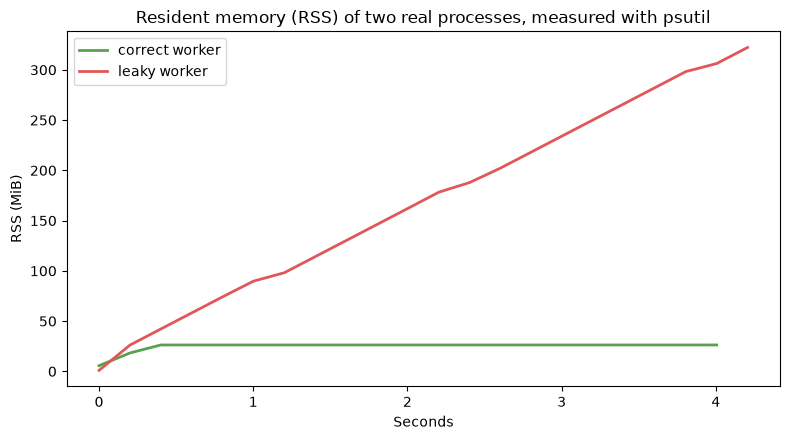

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
for kind, color, label in [("ok", "#59A14F", "correct worker"), ("leak", "#E15759", "leaky worker")]:
    t, m = zip(*samples[kind])
    ax.plot(t, m, lw=2, color=color, label=label)
ax.set(title="Resident memory (RSS) of two real processes, measured with psutil", xlabel="Seconds",
       ylabel="RSS (MiB)")
ax.legend()
plt.tight_layout()
plt.show()

The correct worker stays flat; the leaky worker grows by about 8 MiB per batch. If memory runs out, the Linux **OOM killer** (out-of-memory killer) selects a process, usually the one with the largest memory use, and sends it `SIGKILL`. In Kubernetes (M32) a container that exceeds its memory limit is killed the same way, with the status `OOMKilled`.

*Insight: When a job is slow or killed, measure before you guess: `top`/`htop` for CPU and memory, `df -h` for disk, `dmesg` or the container status for OOM kills. A rising memory curve over time is the signature of a leak.*

## Real-World Use Case or Analogy

Processes are like **workers in a kitchen**, and resources are the **stoves, counters and fridge space**. The head chef (`top`) watches who uses which stove. A worker who keeps every used bowl on the counter (a memory leak) slowly takes all the space, until the manager sends the worker home (the OOM killer). Asking politely first (`SIGTERM`) lets the worker clean up; pushing them out (`SIGKILL`) leaves a mess.

ML engineers check `nvidia-smi` and `htop` while a training job runs, watch memory curves in Grafana (M34) to find leaks in data loaders, and use `SIGTERM` handlers so that a job saves a checkpoint before a spot instance is reclaimed (M33).